# Dataset and ontology overview

Explore the saved graph and questions used in the RLVR tutorial. Figures are exported as PNG, SVG and PDF for presentation slides.

In [1]:
from pathlib import Path
import os, sys, json

PROJECT_ROOT = Path(os.environ.get("KG_RLVR_PROJECT_ROOT", next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/kg_rlvr").exists())))
sys.path.insert(0, str(PROJECT_ROOT / "src"))
DATA_ROOT = Path(os.environ.get("KG_RLVR_DATA_DIR", PROJECT_ROOT / "data"))
OUTPUT_DIR = Path(os.environ.get("KG_RLVR_EDA_OUTPUT_DIR", PROJECT_ROOT / "artifacts/eda"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, FileLink
from kg_rlvr.graph_index import GraphIndex
from kg_rlvr.data import load_tasks
from kg_rlvr.eda import (
    STYLE, question_tables, graph_statistics, save_figure,
    ontology_figure, composition_figure, questions_figure, navigation_figure,
)

graph = GraphIndex.load(DATA_ROOT / "graph")
source, eligible, unique = question_tables(graph, DATA_ROOT)
figures = OUTPUT_DIR / "figures"

def show_figure(builder, filename, *args):
    with plt.rc_context(STYLE):
        fig = builder(*args)
        save_figure(fig, figures, filename)
        plt.show()
        plt.close(fig)

/Users/alirezaak/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Graph and question counts

Stored facts exclude RDF schema and labels. Single-answer instances merge paraphrases of the same starting entity and relation program.

In [2]:
display(graph_statistics(graph).to_frame())
question_counts = pd.DataFrame({
    "Source question rows": source.groupby("split").size(),
    "Single-answer rows": eligible.groupby("split").size(),
    "Unique single-answer instances": unique.groupby("split").size(),
}).reindex(["train", "test"])
display(question_counts)
question_counts.to_csv(OUTPUT_DIR / "question_counts.csv")
display(pd.DataFrame.from_dict(graph.relations, orient="index").rename_axis("relation"))

,Saved graph
Entities,2000
Stored navigation facts,5000
Entity types,8
Relation types,16
Weakly connected components,1
Isolated entities,0


,Source question rows,Single-answer rows,Unique single-answer instances
split,,,
train,2667,2449,1226
test,1067,983,493


,domain,range,inverse_supported,symmetric,cardinality
relation,,,,,
collaborates_with,researcher,researcher,False,True,many_to_many
partners_with,university,university,False,True,many_to_many
authored_by,publication,researcher,True,False,many_to_many
based_in,funder,city,True,False,many_to_one
cites,publication,publication,True,False,many_to_many
city_in_country,city,country,True,False,many_to_one
contributes_to,researcher,project,True,False,many_to_many
funded_by,project,funder,True,False,many_to_many
investigates,project,field,True,False,many_to_many


## 2. Ontology

Each box represents an entity class; each arrow is a stored relation type. Tools also expose permitted inverse operations. The complete ontology and graph live in `data/graph/graph.ttl`.

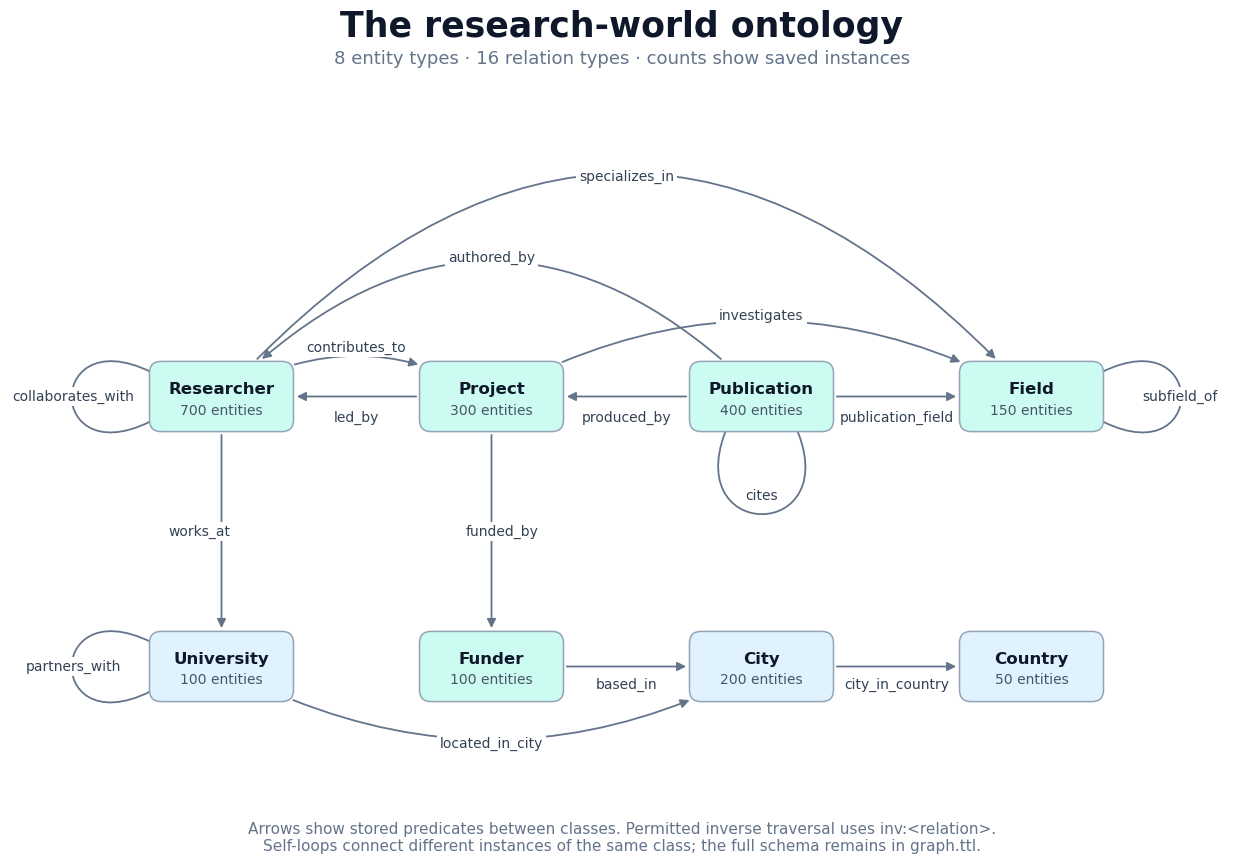

In [3]:
show_figure(ontology_figure, "ontology", graph)

## 3. Graph composition

Entity and relation frequencies show the graph's scale and imbalance.

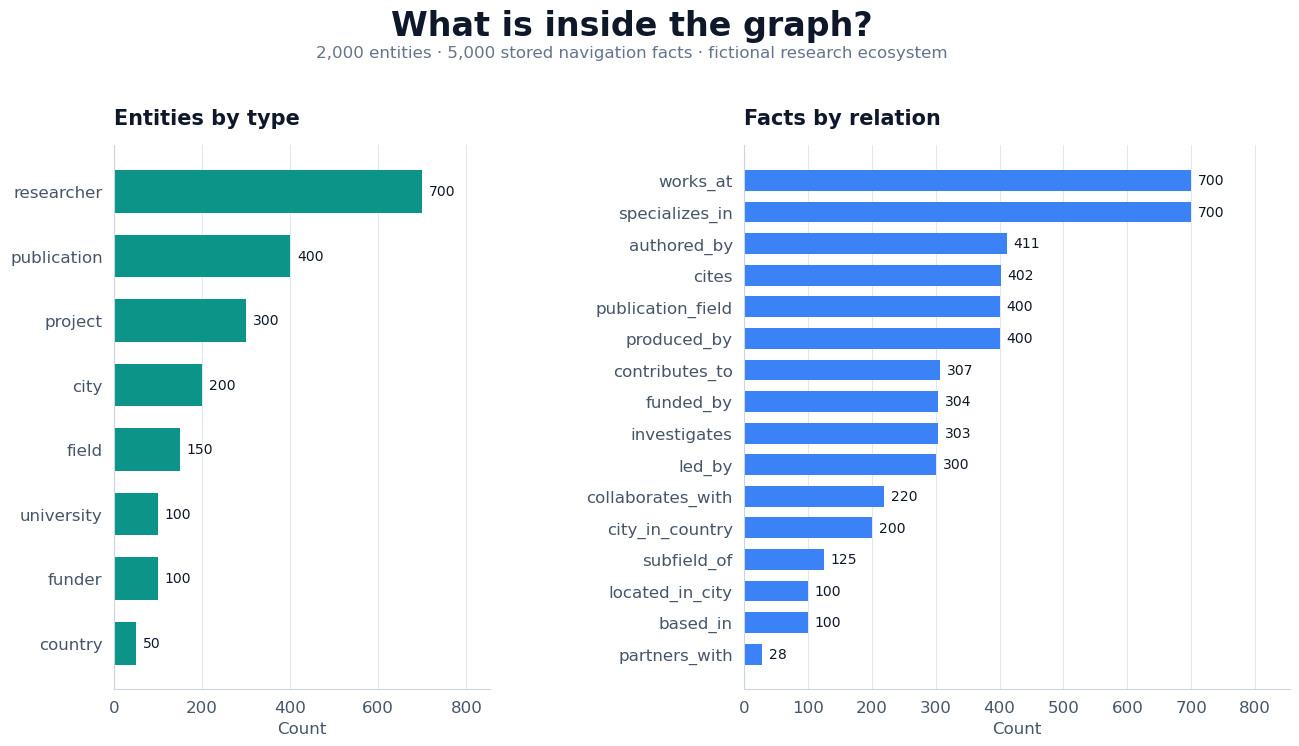

In [4]:
show_figure(composition_figure, "graph_composition", graph)

## 4. Question coverage

The experiment filters for one gold answer, merges paraphrases, reserves SFT questions, then selects the GRPO pool. Training uses hops 1–3; the shared test includes hops 1–4.

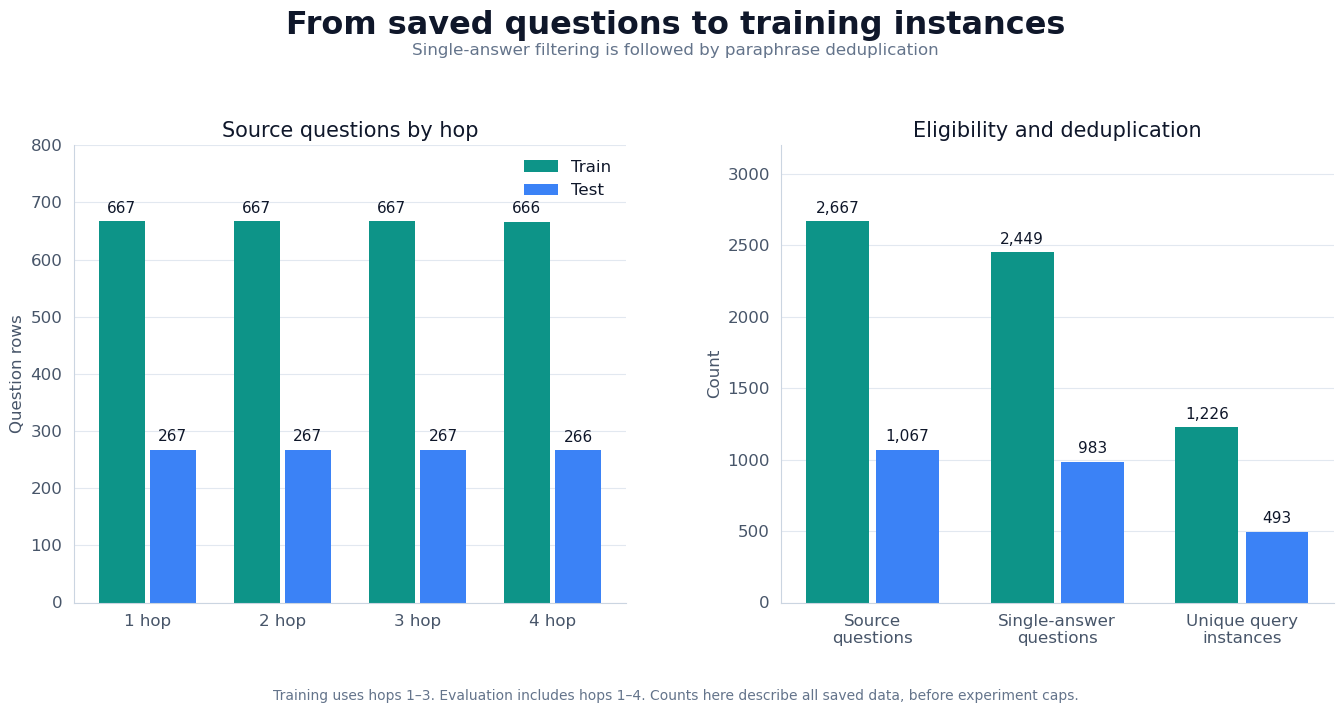

split,test,train
hops,,
1,125,317
2,125,309
3,125,307
4,118,293


In [5]:
show_figure(questions_figure, "question_coverage", source, eligible, unique)
display(pd.crosstab(unique.hop_count, unique.split).rename_axis("hops"))

## 5. Navigation and episode budget

Reference routes list relations before each traversal and finish with a submission. Multiple relation choices remain possible even when a question has one answer.

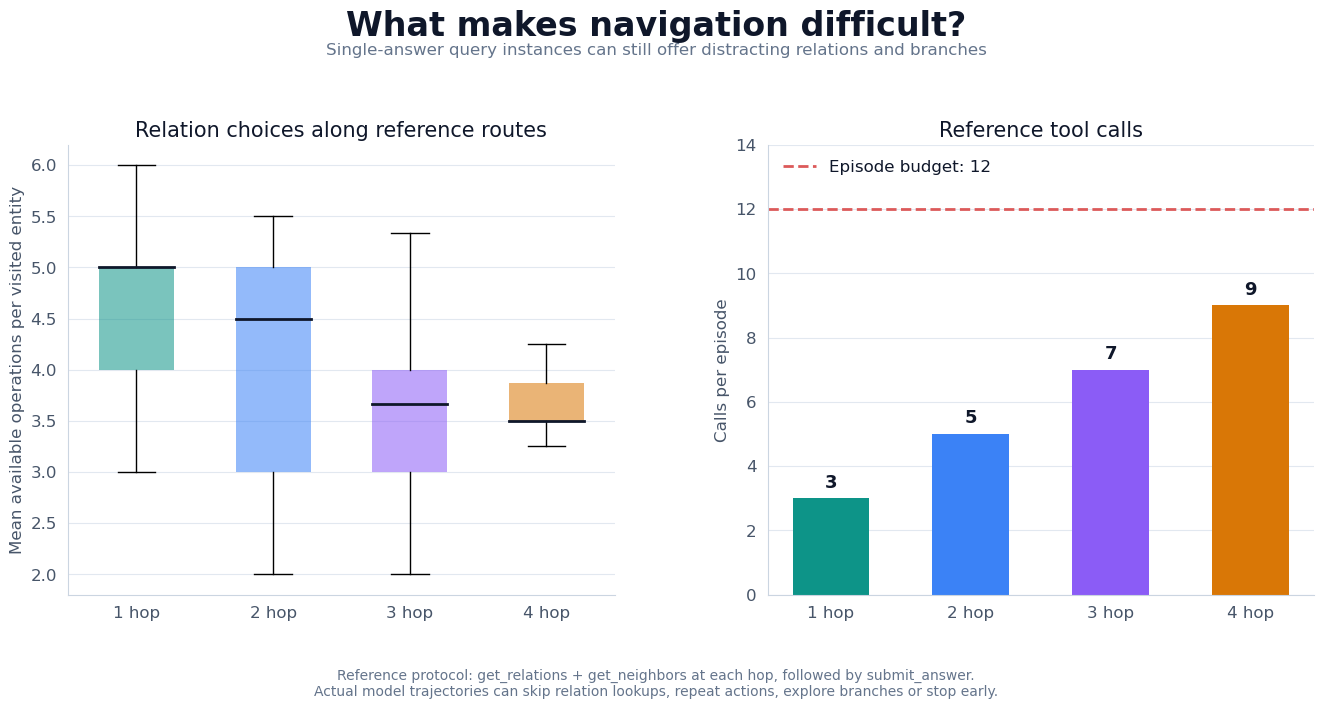

In [6]:
show_figure(navigation_figure, "navigation_difficulty", unique, 12)

## 6. Split assumptions

Train and test share graph entities and relation types. Query instances are separated. SFT and GRPO reserve different instances from the training split.

In [7]:
train = unique[unique.split == "train"]
test = unique[unique.split == "test"]
shared_instances = len(set(train.instance) & set(test.instance))
shared_starts = len(set(train.start_entity) & set(test.start_entity))
display(pd.Series({
    "Shared train/test query instances": shared_instances,
    "Shared starting entities": shared_starts,
    "Available training instances (hops 1–3)": int(train.hop_count.isin([1, 2, 3]).sum()),
    "Available test instances (hops 1–4)": len(test),
}, name="Experiment population").to_frame())

,Experiment population
Shared train/test query instances,0
Shared starting entities,225
Available training instances (hops 1–3),933
Available test instances (hops 1–4),493


## 7. Example model input and private reference

The model receives the question and starting entity. Gold answers and relation programs stay in the verifier and SFT demonstrations.

In [8]:
_, store = load_tasks(DATA_ROOT, max_tool_calls=12, single_answer_only=True)
examples = [store.record(store.select("test", [hop], count=1, seed=41)[0]) for hop in [1, 2, 3, 4]]
display(pd.DataFrame([
    {"hops": q["hop_count"], "question": q["question"], "start": q["start_entity"],
     "private reference": " → ".join(q["relation_path"]), "gold": q["answer_ids"][0]}
    for q in examples
]).style.set_properties(**{"white-space": "normal", "text-align": "left"}))
display(pd.DataFrame(store.prompt(examples[1]["id"])))
summary = {**graph_statistics(graph).to_dict(), "source_question_rows": len(source),
           "single_answer_rows": len(eligible), "unique_single_answer_instances": len(unique),
           "shared_query_instances": shared_instances}
(OUTPUT_DIR / "statistics.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Slide figures:", figures)
for path in sorted(figures.glob("*.svg")):
    display(FileLink(str(path)))

,hops,question,start,private reference,gold
0,1,Which university employs Dr. Nuvthaekyr 0574?,researcher_000573,works_at,university_000072
1,2,In which city is the university employing Dr. Ithorvvex 0289 located?,researcher_000288,works_at → located_in_city,city_000125
2,3,Which country contains a city hosting an organization funding Project Nuvorvith 0249?,project_000248,funded_by → based_in → city_in_country,country_000045
3,4,Which country contains a city hosting a university employing a leader of Project Orvxelzae 0241?,project_000240,led_by → works_at → located_in_city → city_in_country,country_000042


,role,content
0,system,Navigate the fictional research graph to answe...
1,user,Question: In which city is the university empl...


Slide figures: /private/Users/alirezaak/Documents/research/graph_rlvr/artifacts/eda/figures


/private/Users/alirezaak/Documents/research/graph_rlvr/artifacts/eda/figures/graph_composition.svg

/private/Users/alirezaak/Documents/research/graph_rlvr/artifacts/eda/figures/navigation_difficulty.svg

/private/Users/alirezaak/Documents/research/graph_rlvr/artifacts/eda/figures/ontology.svg

/private/Users/alirezaak/Documents/research/graph_rlvr/artifacts/eda/figures/question_coverage.svg